## TASK 01 — Encode, Split, and Standardize

### Objective
Prepare the Titanic dataset for Logistic Regression.

### What we do
1. Convert `Sex` into binary values:
   - female → 1
   - male → 0
2. Separate:
   - `X` = input features
   - `y` = target (`Survived`)
3. Split the data:
   - 80% training
   - 20% testing
   - `stratify=y` keeps the class proportion similar in train and test.
4. Standardize features using `StandardScaler`.
   - Fit the scaler only on training data.
   - Apply the same transformation to both training and test data.

### Why stratified splitting is important
Classification datasets can have unequal numbers of classes. Stratification keeps approximately the same proportion of class 0 and class 1 in both training and test sets.

### What leakage occurs if test data is scaled together?
If we fit the scaler using both training and test data, the mean and standard deviation of the test data become known during preprocessing.

This is **data leakage** because information from the test set enters the model-development process.

Correct approach:

Training data → `fit()` + `transform()`

Test data → `transform()` only

### Done When
- `Sex` is encoded.
- `X` and `y` are separated.
- 80/20 stratified split is created.
- Features are standardized using training data only.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("titanic.csv")

# Encode Sex: female = 1, male = 0
df["Sex"] = (df["Sex"] == "female").astype(int)

# Separate features and target
X = df.drop(columns=["Survived"])
y = df["Survived"].values

# Train-test split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize using training data ONLY
scaler = StandardScaler().fit(X_train)

X_tr = scaler.transform(X_train)
X_te = scaler.transform(X_test)

print("Training shape:", X_tr.shape)
print("Testing shape:", X_te.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training shape: (800, 6)
Testing shape: (200, 6)
Training target shape: (800,)
Testing target shape: (200,)


## TASK 02 — Sigmoid Function and Log-Loss

### Objective
Understand how Logistic Regression converts any value into a probability between 0 and 1.

### Sigmoid Function

The sigmoid function is:

\[
\sigma(z)=\frac{1}{1+e^{-z}}
\]

It converts the model's raw output `z` into a probability.

- Large negative `z` → probability close to 0
- `z = 0` → probability = 0.5
- Large positive `z` → probability close to 1

A probability of `0.5` is commonly used as the decision threshold:

- `p >= 0.5` → class 1
- `p < 0.5` → class 0

### Binary Cross-Entropy / Log-Loss

For one example:

\[
L=-[y\log(p)+(1-y)\log(1-p)]
\]

For `y = 1`, this becomes:

\[
L=-\log(p)
\]

#### Manual calculation

For `y = 1, p = 0.9`:

\[
L=-\log(0.9)\approx0.1054
\]

For `y = 1, p = 0.05`:

\[
L=-\log(0.05)\approx2.9957
\]

Therefore, predicting `0.9` when the actual class is `1` gives a small penalty, while predicting `0.05` gives a much larger penalty.

### Key Logic

The sigmoid gives the probability, while Log-Loss measures how good that probability prediction is.

The more confidently the model predicts the wrong class, the larger the Log-Loss.


z values:        [-10  -1   0   1  10]
sigmoid(z):      [4.53978687e-05 2.68941421e-01 5.00000000e-01 7.31058579e-01
 9.99954602e-01]


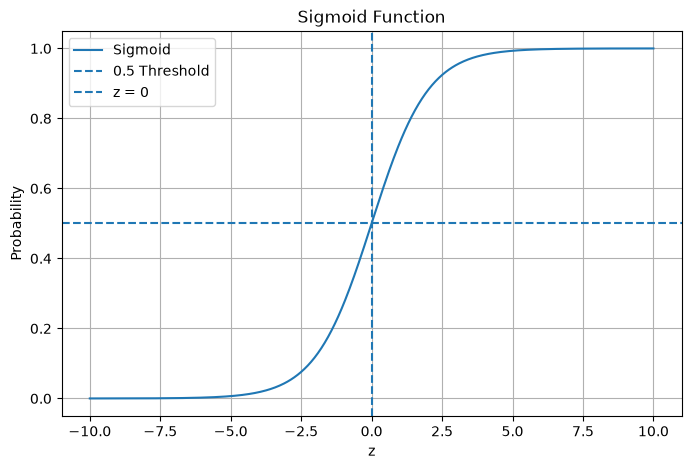

Loss for y=1, p=0.9  : 0.1054
Loss for y=1, p=0.05 : 2.9957


In [7]:
# TASK 02 — Sigmoid Function and Log-Loss

import numpy as np
import matplotlib.pyplot as plt

# Vectorized sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


# Test sigmoid with multiple values
test_values = np.array([-10, -1, 0, 1, 10])
print("z values:       ", test_values)
print("sigmoid(z):     ", sigmoid(test_values))


# Plot sigmoid S-curve
z = np.linspace(-10, 10, 500)
p = sigmoid(z)

plt.figure(figsize=(8, 5))
plt.plot(z, p, label="Sigmoid")
plt.axhline(0.5, linestyle="--", label="0.5 Threshold")
plt.axvline(0, linestyle="--", label="z = 0")

plt.xlabel("z")
plt.ylabel("Probability")
plt.title("Sigmoid Function")
plt.legend()
plt.grid(True)
plt.show()


# Binary Cross-Entropy penalty by hand
y = 1

p_good = 0.9
p_bad = 0.05

loss_good = -(y * np.log(p_good) + (1 - y) * np.log(1 - p_good))
loss_bad = -(y * np.log(p_bad) + (1 - y) * np.log(1 - p_bad))

print(f"Loss for y=1, p=0.9  : {loss_good:.4f}")
print(f"Loss for y=1, p=0.05 : {loss_bad:.4f}")

## TASK 03 — Logistic Regression from Scratch

### Objective
Build Logistic Regression without using `sklearn.LogisticRegression`.

The model learns weights `w` and bias `b` using Gradient Descent.

### Model steps

1. Calculate the linear output:
\[
z = Xw + b
\]

2. Convert `z` into probabilities using sigmoid:
\[
p = sigmoid(z)
\]

3. Calculate gradients:
\[
dw = \frac{1}{m}X^T(p-y)
\]

\[
db = \frac{1}{m}\sum(p-y)
\]

4. Update weights and bias:
\[
w = w - lr \times dw
\]

\[
b = b - lr \times db
\]

5. Repeat for 2000 iterations.

### Why Gradient Descent?
Gradient Descent repeatedly changes `w` and `b` in the direction that reduces the loss.

### Expected result
The training loss should generally decrease as iterations increase. A decreasing loss curve shows that the model is learning and moving toward a lower-loss solution.

The learned weights are printed at the end to see how strongly each feature contributes to the prediction.

Learned weights:
[-0.69650443  1.16607214 -0.06097179 -0.21233038 -0.04322593  0.12174285]

Learned bias:
-0.2780494498294211


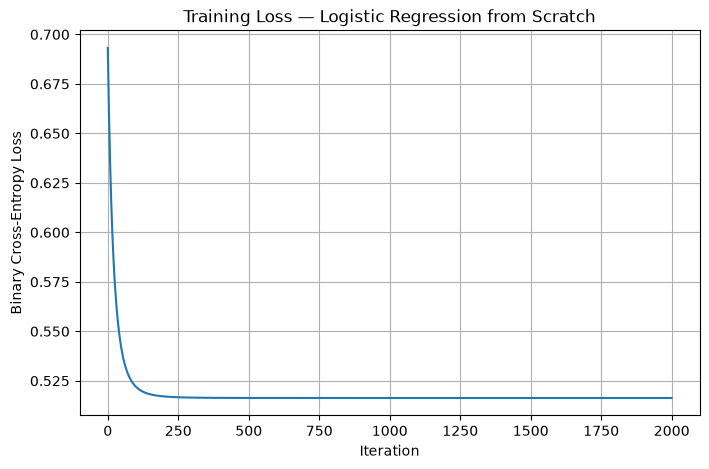

In [8]:
# TASK 03 — Logistic Regression from Scratch

import numpy as np
import matplotlib.pyplot as plt


class LogisticRegressionScratch:

    def __init__(self, learning_rate=0.1, n_iters=2000):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.w = None
        self.b = None
        self.loss_history = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):

        # Number of samples and features
        m, n = X.shape

        # Initialize weights and bias
        self.w = np.zeros(n)
        self.b = 0

        # Gradient Descent
        for i in range(self.n_iters):

            # Forward pass
            z = X @ self.w + self.b
            p = self.sigmoid(z)

            # Avoid log(0)
            p_clip = np.clip(p, 1e-15, 1 - 1e-15)

            # Binary Cross-Entropy loss
            loss = -(1 / m) * np.sum(
                y * np.log(p_clip) +
                (1 - y) * np.log(1 - p_clip)
            )

            self.loss_history.append(loss)

            # Gradients
            dw = (1 / m) * (X.T @ (p - y))
            db = (1 / m) * np.sum(p - y)

            # Update weights and bias
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

        return self

    def predict_proba(self, X):
        z = X @ self.w + self.b
        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)


# Create and train the model
scratch_model = LogisticRegressionScratch(
    learning_rate=0.1,
    n_iters=2000
)

scratch_model.fit(X_tr, y_train)


# Print learned parameters
print("Learned weights:")
print(scratch_model.w)

print("\nLearned bias:")
print(scratch_model.b)


# Plot training loss
plt.figure(figsize=(8, 5))
plt.plot(scratch_model.loss_history)

plt.xlabel("Iteration")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss — Logistic Regression from Scratch")
plt.grid(True)
plt.show()

## TASK 04 — Method 2: Scikit-Learn Parity Proof

### Objective
Train Logistic Regression using Scikit-Learn and verify that it produces nearly the same parameters and predictions as our from-scratch implementation.

### What we do

1. Fit Scikit-Learn's `LogisticRegression` on the already standardized training data.
2. Compare:
   - Bias/intercept
   - Feature weights
3. Calculate the maximum difference between the two implementations.
4. Verify that the maximum difference is less than `10^-3`.
5. Compare predictions on the test set.

### Why do we compare them?
This is a **parity proof**. If our implementation is correct, its learned weights and predictions should be almost identical to the trusted Scikit-Learn implementation.

### Parity condition

\[
|w_{scratch}-w_{sklearn}| < 10^{-3}
\]

and similarly for the intercept.

### Done When
- Scikit-Learn model is fitted.
- Weights and intercept are displayed side-by-side.
- Maximum parameter difference is below `10^-3`.
- Test-set predictions match.

In [9]:
# TASK 04 — Scikit-Learn Parity Proof

from sklearn.linear_model import LogisticRegression

# Train Scikit-Learn Logistic Regression
sk_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=1000
)

sk_model.fit(X_tr, y_train)


# Compare intercept and feature weights
parity_df = pd.DataFrame({
    "Scratch": [scratch_model.b] + list(scratch_model.w),
    "Sklearn": [sk_model.intercept_[0]] + list(sk_model.coef_[0])
})

print("Parameter comparison:")
print(parity_df)


# Calculate absolute differences
differences = np.abs(
    parity_df["Scratch"] - parity_df["Sklearn"]
)

print("\nMaximum parameter difference:", differences.max())

# Verify parameter parity
parameter_parity = differences.max() < 1e-3

print("Weights/intercept match within 1e-3:", parameter_parity)


# Compare test-set predictions
scratch_predictions = scratch_model.predict(X_te)
sklearn_predictions = sk_model.predict(X_te)

predictions_match = np.array_equal(
    scratch_predictions,
    sklearn_predictions
)

print("Test predictions match:", predictions_match)


# Optional: show number of different predictions
different_predictions = np.sum(
    scratch_predictions != sklearn_predictions
)

print("Number of different test predictions:", different_predictions)

Parameter comparison:
    Scratch   Sklearn
0 -0.278049 -0.278052
1 -0.696504 -0.696723
2  1.166072  1.166253
3 -0.060972 -0.061025
4 -0.212330 -0.212460
5 -0.043226 -0.043259
6  0.121743  0.121748

Maximum parameter difference: 0.00021840642081483175
Weights/intercept match within 1e-3: True
Test predictions match: True
Number of different test predictions: 0


d:\AI ML Internship\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# TASK 05 — Confusion Matrix and Classification Metrics

## 1. Confusion Matrix

A confusion matrix shows how many predictions were correct and incorrect for each class.

- **TP (True Positive):** Actual positive and predicted positive.
- **TN (True Negative):** Actual negative and predicted negative.
- **FP (False Positive):** Actual negative but predicted positive.
- **FN (False Negative):** Actual positive but predicted negative.

For fraud detection:
- Positive = Fraud
- Negative = Not Fraud

## 2. Classification Metrics

### Accuracy
Measures the overall percentage of correct predictions.

**Formula:**
Accuracy = (TP + TN) / (TP + TN + FP + FN)

### Precision
Of all transactions predicted as fraud, how many were actually fraud?

**Formula:**
Precision = TP / (TP + FP)

### Recall
Of all actual fraudulent transactions, how many did the model detect?

**Formula:**
Recall = TP / (TP + FN)

### F1-Score
Harmonic mean of Precision and Recall. It is useful when both false positives and false negatives are important.

**Formula:**
F1 = 2 × (Precision × Recall) / (Precision + Recall)

## 3. Why 99% Accuracy Can Be Disastrous in Fraud Detection

Credit card fraud data is usually highly imbalanced: most transactions are legitimate and only a small percentage are fraudulent.

For example, if 99 out of 100 transactions are legitimate, a model that predicts **every transaction as "Not Fraud"** will achieve 99% accuracy.

However:
- TP = 0
- FN = 1
- Recall = 0

This means the model detects **0% of the fraud**, even though its accuracy is 99%.

Therefore, accuracy alone is not a good metric for highly imbalanced fraud detection. Precision, Recall, F1-Score, and the Confusion Matrix should also be considered.

## 4. Key Logic

The steps are:

1. Generate predictions on the test set.
2. Compare actual (`y_test`) and predicted (`y_pred`) labels.
3. Calculate TP, TN, FP, and FN using the confusion matrix.
4. Plot the confusion matrix as a heatmap.
5. Calculate Accuracy, Precision, Recall, and F1-Score.
6. Interpret the metrics, especially Recall for fraud detection.

**Lookup Q: Why is Recall important for fraud detection?**  
**Answer:** Recall tells us how many actual fraudulent transactions the model successfully detects. Low Recall means many fraudulent transactions are being missed.

Confusion Matrix:
[[86 26]
 [21 67]]

Confusion Matrix Values:
True Negative (TN): 86
False Positive (FP): 26
False Negative (FN): 21
True Positive (TP): 67

Classification Metrics:
Accuracy : 0.7650
Precision: 0.7204
Recall   : 0.7614
F1-Score : 0.7403


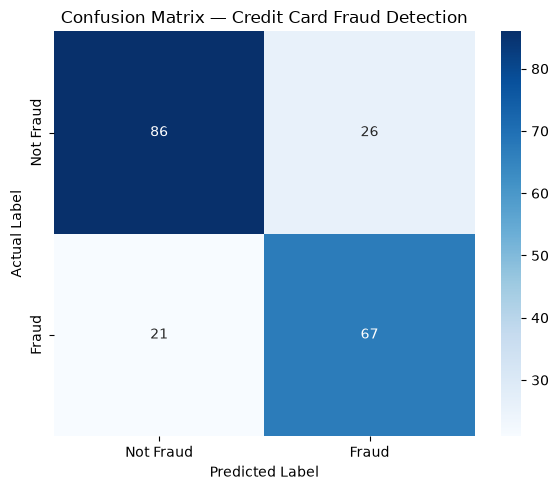

In [11]:
# TASK 05 — Confusion Matrix and Classification Metrics

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. Generate predictions on the test set
# ------------------------------------------------------------

y_pred = sk_model.predict(X_te)

# ------------------------------------------------------------
# 2. Calculate Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

TN, FP, FN, TP = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nConfusion Matrix Values:")
print("True Negative (TN):", TN)
print("False Positive (FP):", FP)
print("False Negative (FN):", FN)
print("True Positive (TP):", TP)

# ------------------------------------------------------------
# 3. Calculate Classification Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\nClassification Metrics:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

# ------------------------------------------------------------
# 4. Plot Confusion Matrix Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Fraud", "Fraud"],
    yticklabels=["Not Fraud", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Credit Card Fraud Detection")

plt.tight_layout()
plt.show()

# TASK 06 — Decision Threshold Tuning and ROC-AUC Curve

## 1. Predicted Probabilities

`predict_proba()` gives the probability that each transaction belongs to the positive class (Fraud).

We use:

`probs = sk_model.predict_proba(X_te)[:, 1]`

The `[:, 1]` selects the probability of class **1 (Fraud)**.

## 2. Decision Threshold

A classification threshold converts predicted probabilities into class predictions.

- Probability >= threshold → Fraud (1)
- Probability < threshold → Not Fraud (0)

We test thresholds **0.2, 0.5, and 0.8**.

### Precision-Recall Trade-off

- **Lower threshold (0.2):** The model classifies more transactions as fraud. This generally increases Recall but can decrease Precision because more legitimate transactions may be classified as fraud.
- **Medium threshold (0.5):** Standard classification threshold.
- **Higher threshold (0.8):** The model requires stronger evidence before predicting fraud. This generally increases Precision but can decrease Recall because some fraud cases may be missed.

The exact Precision and Recall values depend on the test data and trained model.

## 3. ROC Curve

The ROC curve shows the relationship between:

- **TPR (True Positive Rate / Recall):** TP / (TP + FN)
- **FPR (False Positive Rate):** FP / (FP + TN)

Different classification thresholds produce different TPR and FPR values.

## 4. ROC-AUC

ROC-AUC represents how well the model separates the positive and negative classes across different thresholds.

- AUC close to 1 → strong class separation
- AUC around 0.5 → approximately random classification

## 5. Medical Diagnosis: Precision or Recall?

For many medical diagnosis systems, **high Recall can be especially important** because missing a patient who actually has a disease (False Negative) can have serious consequences.

However, Precision is also important because too many False Positives can lead to unnecessary tests, costs, anxiety, or treatment.

Therefore, the appropriate balance depends on the specific disease, consequences of False Negatives and False Positives, and clinical requirements.

**Lookup Q: What happens when the threshold is decreased?**  
**Answer:** More cases are classified as positive. Recall generally increases, while Precision may decrease.

**Lookup Q: What does ROC-AUC measure?**  
**Answer:** It measures the model's ability to distinguish between positive and negative classes across different classification thresholds.

Precision-Recall at Different Thresholds:
 Threshold  Precision   Recall
       0.2   0.618321 0.920455
       0.5   0.720430 0.761364
       0.8   1.000000 0.375000


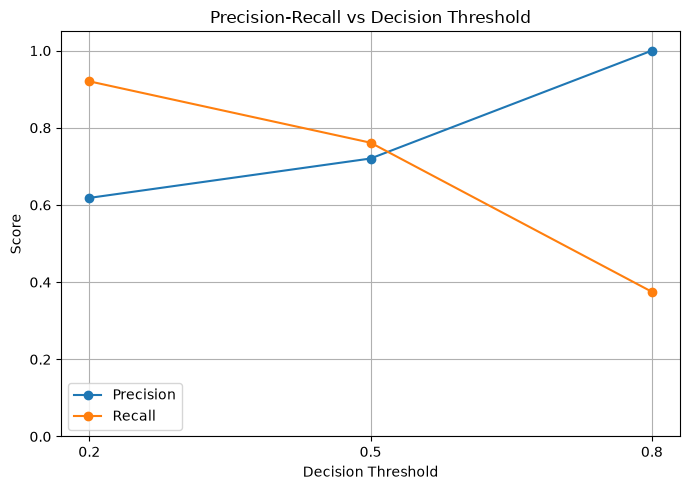


ROC-AUC Score: 0.8643


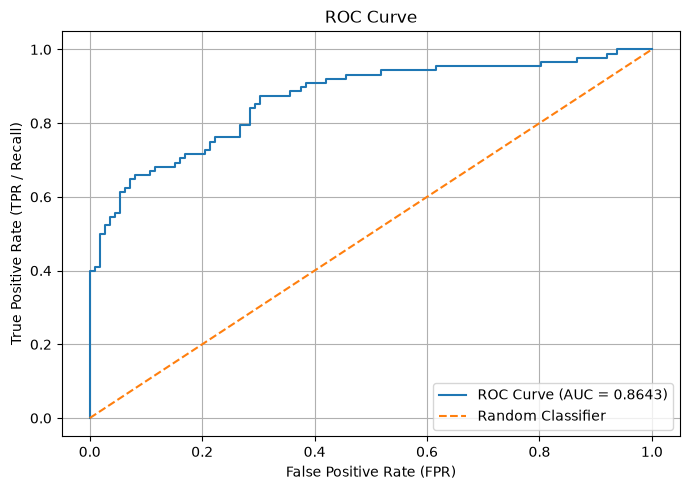

In [12]:
# TASK 06 — Decision Threshold Tuning and ROC-AUC

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------------------
# 1. Extract predicted probabilities
# ------------------------------------------------------------

probs = sk_model.predict_proba(X_te)[:, 1]

# ------------------------------------------------------------
# 2. Test different decision thresholds
# ------------------------------------------------------------

thresholds = [0.2, 0.5, 0.8]

results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = (probs >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall
    })

# Display results
threshold_results = pd.DataFrame(results)

print("Precision-Recall at Different Thresholds:")
print(threshold_results.to_string(index=False))

# ------------------------------------------------------------
# 3. Plot Precision and Recall vs Threshold
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall vs Decision Threshold")
plt.xticks(thresholds)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Calculate ROC Curve
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    probs
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    probs
)

print(f"\nROC-AUC Score: {roc_auc:.4f}")

# ------------------------------------------------------------
# 5. Plot ROC Curve
# ------------------------------------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.4f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR / Recall)")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# TASK 07 — Odds Ratios and Plain-English Model Interpretation

## 1. Feature Weights

Logistic Regression assigns a weight (`w`) to every feature.

- **Positive weight:** Increasing the feature increases the predicted log-odds of survival.
- **Negative weight:** Increasing the feature decreases the predicted log-odds of survival.
- **Weight close to 0:** The feature has relatively little effect on the prediction.

## 2. Odds Ratio

The Odds Ratio is calculated as:

**Odds Ratio = e^w**

Interpretation:

- **OR > 1:** The feature increases the odds of survival.
- **OR < 1:** The feature decreases the odds of survival.
- **OR = 1:** The feature has no effect on the odds.

For example, an Odds Ratio of 2 means the odds of survival are approximately 2 times higher for a one-unit increase in that feature, assuming other features remain constant.

## 3. Titanic Survival Interpretation

The Logistic Regression coefficients show how the demographic and other input features are associated with survival.

A positive coefficient indicates that higher values of that feature are associated with higher predicted survival odds, while a negative coefficient indicates lower predicted survival odds.

For Titanic data, passenger characteristics such as **sex, passenger class, and age** can be important drivers of survival predictions. The exact direction and magnitude should be interpreted from the calculated coefficients and Odds Ratios rather than assumed beforehand.

The model coefficients describe statistical associations in the dataset; they do not by themselves establish causation.

## 4. Key Logic

1. Extract feature weights from `sk_model.coef_[0]`.
2. Calculate Odds Ratio using `np.exp(weight)`.
3. Create a table containing each feature, its weight, and its Odds Ratio.
4. Plot the feature weights horizontally.
5. Use positive/negative weights to explain the model in plain English.

**Lookup Q: What does a positive coefficient mean?**  
**Answer:** It means the feature increases the log-odds of the positive class (survival), assuming other features remain constant.

**Lookup Q: What does an Odds Ratio below 1 mean?**  
**Answer:** It means the feature is associated with lower odds of the positive class for a one-unit increase in that feature, holding other features constant.

Feature Weights and Odds Ratios:
  Feature    Weight  Odds_Ratio
Feature_0 -0.696723    0.498215
Feature_1  1.166253    3.209942
Feature_2 -0.061025    0.940799
Feature_3 -0.212460    0.808593
Feature_4 -0.043259    0.957663
Feature_5  0.121748    1.129470


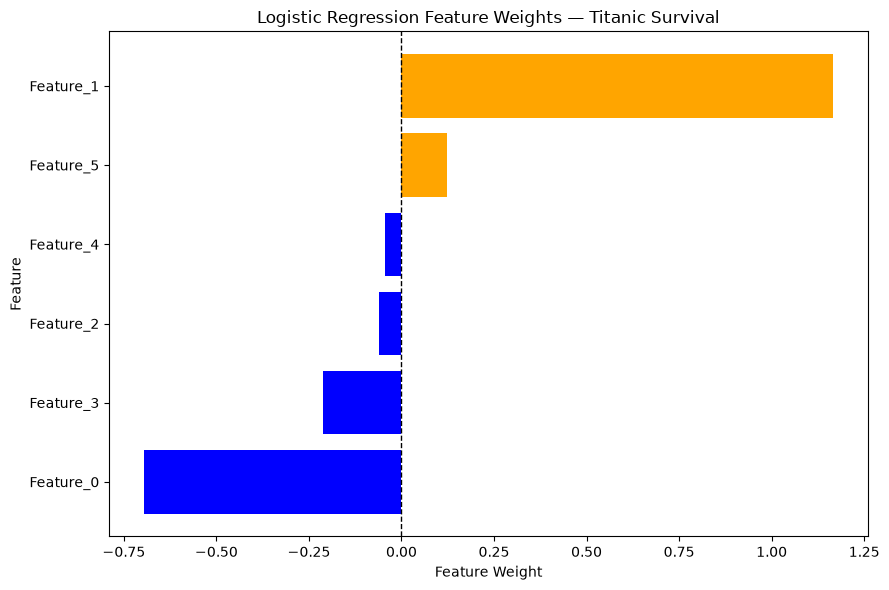

In [13]:
# TASK 07 — Odds Ratios and Plain-English Model Interpretation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Get feature weights from the trained Logistic Regression
# ------------------------------------------------------------

weights = sk_model.coef_[0]

# ------------------------------------------------------------
# 2. Get feature names
# ------------------------------------------------------------

# If X_tr is a pandas DataFrame, use its column names.
# Otherwise, create generic feature names.
if hasattr(X_tr, "columns"):
    feature_names = X_tr.columns.tolist()
else:
    feature_names = [f"Feature_{i}" for i in range(X_tr.shape[1])]

# ------------------------------------------------------------
# 3. Calculate Odds Ratios
# ------------------------------------------------------------

odds_ratios = np.exp(weights)

# Create interpretation table
odds_ratio_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": weights,
    "Odds_Ratio": odds_ratios
})

# Display results
print("Feature Weights and Odds Ratios:")
print(odds_ratio_df.to_string(index=False))

# ------------------------------------------------------------
# 4. Horizontal bar chart of feature weights
# ------------------------------------------------------------

# Sort features by weight for easier interpretation
plot_df = odds_ratio_df.sort_values("Weight")

plt.figure(figsize=(9, 6))

# Positive = orange, Negative = blue
colors = [
    "orange" if weight > 0 else "blue"
    for weight in plot_df["Weight"]
]

plt.barh(
    plot_df["Feature"],
    plot_df["Weight"],
    color=colors
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Feature Weight")
plt.ylabel("Feature")
plt.title("Logistic Regression Feature Weights — Titanic Survival")

plt.tight_layout()
plt.show()